#KNN


## 1. Import Library

Pada tahap ini dilakukan import library yang dibutuhkan untuk membangun model klasifikasi K-Nearest Neighbors (KNN), melakukan preprocessing fitur, mencari parameter terbaik, serta mengevaluasi performa model.

Library NumPy digunakan untuk membaca dan mengolah array fitur. Pandas digunakan untuk mengelola hasil eksperimen. Scikit-learn digunakan untuk proses scaling, pelatihan KNN, hyperparameter tuning, dan evaluasi model. Matplotlib dan Seaborn digunakan untuk visualisasi hasil evaluasi.

In [1]:
# Import library
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Import model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Import tuning
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Import evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Import model saving
import joblib
import json

# Pengaturan tampilan
sns.set_theme(style='whitegrid')
np.random.seed(42)

print('Semua library berhasil di-import.')

Semua library berhasil di-import.


## 2. Integrasi Google Drive

Google Drive digunakan sebagai tempat penyimpanan hasil ekstraksi fitur dari tahap preprocessing. File yang digunakan terdiri dari enam array, yaitu fitur dan label untuk data training, validation, dan testing.

Data tersebut akan digunakan sebagai input dalam proses pembangunan model KNN.

In [2]:
from google.colab import drive

drive.mount('/content/drive')

# Direktori hasil preprocessing
DATA_DIR = '/content/drive/MyDrive/color_detection/hasil_preprocessing'

# Memeriksa direktori
if os.path.exists(DATA_DIR):
    print('Direktori ditemukan:', DATA_DIR)
else:
    raise FileNotFoundError('Direktori preprocessing tidak ditemukan.')

print('\nIsi folder:')
print(os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Direktori ditemukan: /content/drive/MyDrive/color_detection/hasil_preprocessing

Isi folder:
['y_val.npy', 'X_val.npy', 'y_train.npy', 'X_train.npy', 'y_test.npy', 'X_test.npy']


## 3. Load Data Fitur dan Label

Pada tahap ini dilakukan pemuatan data hasil ekstraksi fitur menggunakan format NumPy Array (.npy).

Data terdiri dari:
- X_train dan y_train untuk pelatihan model.
- X_val dan y_val untuk pemilihan konfigurasi model.
- X_test dan y_test untuk evaluasi akhir model.

Setiap gambar direpresentasikan oleh sembilan fitur numerik yang berasal dari tiga warna dominan, dengan masing-masing warna memiliki komponen Red, Green, dan Blue (RGB).

In [3]:
# Load fitur training, validation, dan testing
X_train = np.load(os.path.join(DATA_DIR, 'X_train.npy'))
X_val = np.load(os.path.join(DATA_DIR, 'X_val.npy'))
X_test = np.load(os.path.join(DATA_DIR, 'X_test.npy'))

# Load label
y_train = np.load(os.path.join(DATA_DIR, 'y_train.npy'))
y_val = np.load(os.path.join(DATA_DIR, 'y_val.npy'))
y_test = np.load(os.path.join(DATA_DIR, 'y_test.npy'))

print('Data berhasil dimuat.')

print('\nShape Data:')
print('X_train:', X_train.shape)
print('X_val  :', X_val.shape)
print('X_test :', X_test.shape)

print('\nShape Label:')
print('y_train:', y_train.shape)
print('y_val  :', y_val.shape)
print('y_test :', y_test.shape)

Data berhasil dimuat.

Shape Data:
X_train: (3181, 9)
X_val  : (682, 9)
X_test : (682, 9)

Shape Label:
y_train: (3181,)
y_val  : (682,)
y_test : (682,)


In [4]:
# Memeriksa missing value atau nilai tidak valid
print('Pemeriksaan nilai NaN:')
print('X_train:', np.isnan(X_train).sum())
print('X_val  :', np.isnan(X_val).sum())
print('X_test :', np.isnan(X_test).sum())

print('\nPemeriksaan nilai infinite:')
print('X_train:', np.isinf(X_train).sum())
print('X_val  :', np.isinf(X_val).sum())
print('X_test :', np.isinf(X_test).sum())

# Memeriksa jumlah kelas
print('\nJumlah kelas:', len(np.unique(y_train)))
print('Daftar kelas:', np.unique(y_train))

# Memeriksa dimensi fitur
assert X_train.shape[1] == 9
assert X_val.shape[1] == 9
assert X_test.shape[1] == 9

print('\nValidasi dimensi fitur berhasil.')

Pemeriksaan nilai NaN:
X_train: 0
X_val  : 0
X_test : 0

Pemeriksaan nilai infinite:
X_train: 0
X_val  : 0
X_test : 0

Jumlah kelas: 11
Daftar kelas: ['black' 'blue' 'brown' 'green' 'grey' 'orange' 'pink' 'purple' 'red'
 'white' 'yellow']

Validasi dimensi fitur berhasil.


## 5. Feature Scaling

Feature scaling merupakan proses menyamakan skala nilai fitur agar setiap fitur memiliki kontribusi yang lebih seimbang dalam perhitungan jarak.

Tahap ini penting dalam algoritma K-Nearest Neighbors (KNN), karena klasifikasi dilakukan berdasarkan jarak antara data yang akan diprediksi dengan data training.

Pada penelitian ini akan dibandingkan beberapa pendekatan, yaitu:
1. Tanpa scaling.
2. StandardScaler.
3. MinMaxScaler.
4. RobustScaler.

Proses scaling dilakukan dengan mempelajari parameter hanya dari data training. Data validation dan testing kemudian ditransformasikan menggunakan parameter yang sama untuk menghindari data leakage.

In [5]:
# Menyiapkan beberapa metode scaling
scalers = {
    'No Scaling': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

# Melakukan scaling pada data
scaled_data = {}

for name, scaler in scalers.items():

    if scaler is None:
        X_train_scaled = X_train.copy()
        X_val_scaled = X_val.copy()
        X_test_scaled = X_test.copy()

    else:
        X_train_scaled = scaler.fit_transform(X_train)
        X_val_scaled = scaler.transform(X_val)
        X_test_scaled = scaler.transform(X_test)

    scaled_data[name] = {
        'scaler': scaler,
        'X_train': X_train_scaled,
        'X_val': X_val_scaled,
        'X_test': X_test_scaled
    }

    print(f'{name}:')
    print('  Train:', X_train_scaled.shape)
    print('  Validation:', X_val_scaled.shape)
    print('  Test:', X_test_scaled.shape)

No Scaling:
  Train: (3181, 9)
  Validation: (682, 9)
  Test: (682, 9)
StandardScaler:
  Train: (3181, 9)
  Validation: (682, 9)
  Test: (682, 9)
MinMaxScaler:
  Train: (3181, 9)
  Validation: (682, 9)
  Test: (682, 9)
RobustScaler:
  Train: (3181, 9)
  Validation: (682, 9)
  Test: (682, 9)


In [6]:
# Membandingkan rentang nilai fitur
scaling_summary = []

for name, data in scaled_data.items():

    scaling_summary.append({
        'Scaling': name,
        'Min Value': data['X_train'].min(),
        'Max Value': data['X_train'].max(),
        'Mean Value': data['X_train'].mean(),
        'Std Value': data['X_train'].std()
    })

scaling_df = pd.DataFrame(scaling_summary)

display(scaling_df.round(4))

,Scaling,Min Value,Max Value,Mean Value,Std Value
0,No Scaling,1.7446,254.9834,170.8892,75.8044
1,StandardScaler,-4.3772,2.4031,-0.0000,1.0000
2,MinMaxScaler,0.0000,1.0000,0.6645,0.3027
3,RobustScaler,-104.8411,1.5458,-3.2842,13.6306


## 6. Hyperparameter Tuning KNN

Hyperparameter tuning dilakukan untuk memperoleh konfigurasi model KNN yang memberikan performa klasifikasi terbaik.

Parameter yang diuji meliputi:
- Jumlah tetangga terdekat (K).
- Metode pembobotan tetangga (weights).
- Metrik pengukuran jarak (distance metric).
- Metode feature scaling.

Setiap kombinasi parameter akan dilatih menggunakan data training dan dievaluasi menggunakan data validation. Hasil pengujian digunakan untuk menentukan konfigurasi model yang akan dipilih untuk evaluasi akhir.

In [7]:
# Daftar parameter yang akan diuji
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 21, 25, 31]

weights_values = ['uniform', 'distance']

metrics_values = ['euclidean', 'manhattan']

results = []

# Eksperimen seluruh kombinasi
for scaling_name, data in scaled_data.items():

    for k in k_values:
        for weight in weights_values:
            for metric in metrics_values:

                model = KNeighborsClassifier(
                    n_neighbors=k,
                    weights=weight,
                    metric=metric,
                    n_jobs=-1
                )

                model.fit(data['X_train'], y_train)

                y_pred = model.predict(data['X_val'])

                results.append({
                    'Scaling': scaling_name,
                    'K': k,
                    'Weights': weight,
                    'Metric': metric,
                    'Accuracy': accuracy_score(y_val, y_pred),
                    'Precision': precision_score(
                        y_val, y_pred, average='macro', zero_division=0
                    ),
                    'Recall': recall_score(
                        y_val, y_pred, average='macro', zero_division=0
                    ),
                    'F1-Score': f1_score(
                        y_val, y_pred, average='macro', zero_division=0
                    )
                })

results_df = pd.DataFrame(results)

print('Jumlah eksperimen:', len(results_df))
display(results_df.head())

Jumlah eksperimen: 176


,Scaling,K,Weights,Metric,Accuracy,Precision,Recall,F1-Score
0,No Scaling,3,uniform,euclidean,0.675953,0.701751,0.675249,0.675401
1,No Scaling,3,uniform,manhattan,0.681818,0.700855,0.680827,0.680277
2,No Scaling,3,distance,euclidean,0.693548,0.706068,0.693482,0.692848
3,No Scaling,3,distance,manhattan,0.687683,0.693779,0.687197,0.685910
4,No Scaling,5,uniform,euclidean,0.687683,0.709243,0.686985,0.686194


In [8]:
# Mengurutkan berdasarkan F1-score dan accuracy
results_sorted = results_df.sort_values(
    by=['F1-Score', 'Accuracy'],
    ascending=False
).reset_index(drop=True)

print('10 konfigurasi terbaik:')
display(results_sorted.head(10))

10 konfigurasi terbaik:


,Scaling,K,Weights,Metric,Accuracy,Precision,Recall,F1-Score
0,MinMaxScaler,5,distance,euclidean,0.700880,0.714479,0.700727,0.698442
1,No Scaling,7,distance,euclidean,0.697947,0.721943,0.697578,0.697198
2,MinMaxScaler,7,distance,euclidean,0.697947,0.721184,0.697578,0.696980
3,MinMaxScaler,3,distance,euclidean,0.697947,0.709670,0.697701,0.696858
4,No Scaling,5,distance,euclidean,0.696481,0.711717,0.696230,0.694239
5,MinMaxScaler,7,uniform,euclidean,0.695015,0.718487,0.694506,0.693131
6,No Scaling,3,distance,euclidean,0.693548,0.706068,0.693482,0.692848
7,No Scaling,7,uniform,euclidean,0.693548,0.718019,0.692990,0.691925
8,No Scaling,11,distance,euclidean,0.693548,0.712267,0.693560,0.690472
9,MinMaxScaler,11,distance,euclidean,0.693548,0.712758,0.693560,0.690458


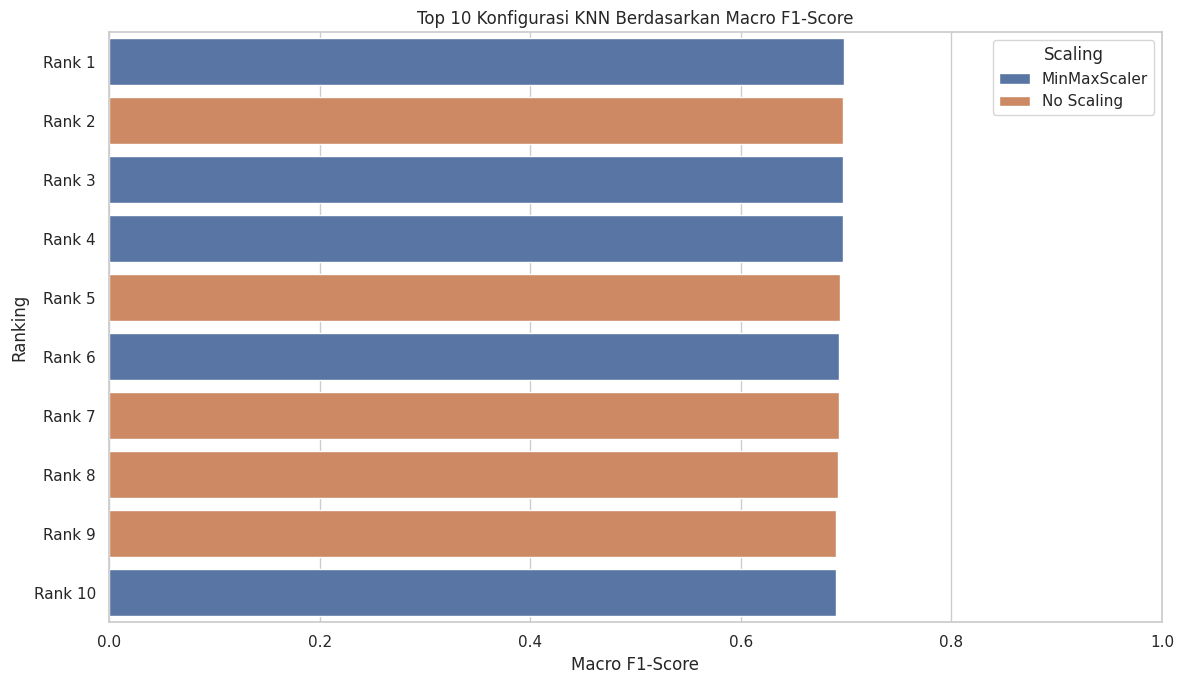

In [9]:
# Mengambil 10 konfigurasi terbaik
top_10 = results_sorted.head(10).copy()

# Membuat label ranking sebagai kategori
top_10['Ranking'] = [
    f'Rank {i}' for i in range(1, len(top_10) + 1)
]

# Membuat grafik horizontal
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10,
    x='F1-Score',
    y='Ranking',
    hue='Scaling',
    orient='h',
    dodge=False
)

plt.title('Top 10 Konfigurasi KNN Berdasarkan Macro F1-Score')
plt.xlabel('Macro F1-Score')
plt.ylabel('Ranking')
plt.xlim(0, 1)
plt.legend(title='Scaling')
plt.tight_layout()
plt.show()

In [10]:
top_10 = results_sorted.head(10)

display(
    top_10[
        ['Scaling', 'K', 'Weights', 'Metric',
         'Accuracy', 'Precision', 'Recall', 'F1-Score']
    ].style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}'
    })
)

,Scaling,K,Weights,Metric,Accuracy,Precision,Recall,F1-Score
0,MinMaxScaler,5,distance,euclidean,0.7009,0.7145,0.7007,0.6984
1,No Scaling,7,distance,euclidean,0.6979,0.7219,0.6976,0.6972
2,MinMaxScaler,7,distance,euclidean,0.6979,0.7212,0.6976,0.6970
3,MinMaxScaler,3,distance,euclidean,0.6979,0.7097,0.6977,0.6969
4,No Scaling,5,distance,euclidean,0.6965,0.7117,0.6962,0.6942
5,MinMaxScaler,7,uniform,euclidean,0.6950,0.7185,0.6945,0.6931
6,No Scaling,3,distance,euclidean,0.6935,0.7061,0.6935,0.6928
7,No Scaling,7,uniform,euclidean,0.6935,0.7180,0.6930,0.6919
8,No Scaling,11,distance,euclidean,0.6935,0.7123,0.6936,0.6905
9,MinMaxScaler,11,distance,euclidean,0.6935,0.7128,0.6936,0.6905


## 7. Evaluasi Konfigurasi KNN Terbaik

Berdasarkan hasil hyperparameter tuning, konfigurasi dengan nilai Macro F1-Score tertinggi dipilih sebagai model terbaik sementara.

Konfigurasi tersebut menggunakan MinMaxScaler dengan nilai K sebesar 5, pembobotan tetangga menggunakan distance, dan metrik jarak Euclidean.

Pada tahap ini, model dilatih kembali menggunakan seluruh data training dan dievaluasi menggunakan data validation untuk memastikan performa konfigurasi terpilih.

In [11]:
# Mengambil konfigurasi terbaik
best_params = results_sorted.iloc[0]

best_scaler = MinMaxScaler()

# Scaling data
X_train_best = best_scaler.fit_transform(X_train)
X_val_best = best_scaler.transform(X_val)

# Membuat model KNN terbaik
best_knn = KNeighborsClassifier(
    n_neighbors=int(best_params['K']),
    weights=best_params['Weights'],
    metric=best_params['Metric'],
    n_jobs=-1
)

# Training
best_knn.fit(X_train_best, y_train)

# Prediksi validation
y_val_pred = best_knn.predict(X_val_best)

print('Model terbaik berhasil dilatih.')

Model terbaik berhasil dilatih.


In [12]:
print('Classification Report - Validation Set\n')

print(
    classification_report(
        y_val,
        y_val_pred,
        zero_division=0
    )
)

Classification Report - Validation Set

              precision    recall  f1-score   support

       black       0.71      0.83      0.77        65
        blue       0.75      0.74      0.75        62
       brown       0.59      0.65      0.62        62
       green       0.76      0.63      0.69        60
        grey       0.51      0.72      0.60        60
      orange       0.71      0.62      0.66        66
        pink       0.70      0.67      0.68        60
      purple       0.81      0.42      0.55        62
         red       0.79      0.79      0.79        63
       white       0.69      0.82      0.75        62
      yellow       0.83      0.82      0.82        60

    accuracy                           0.70       682
   macro avg       0.71      0.70      0.70       682
weighted avg       0.71      0.70      0.70       682



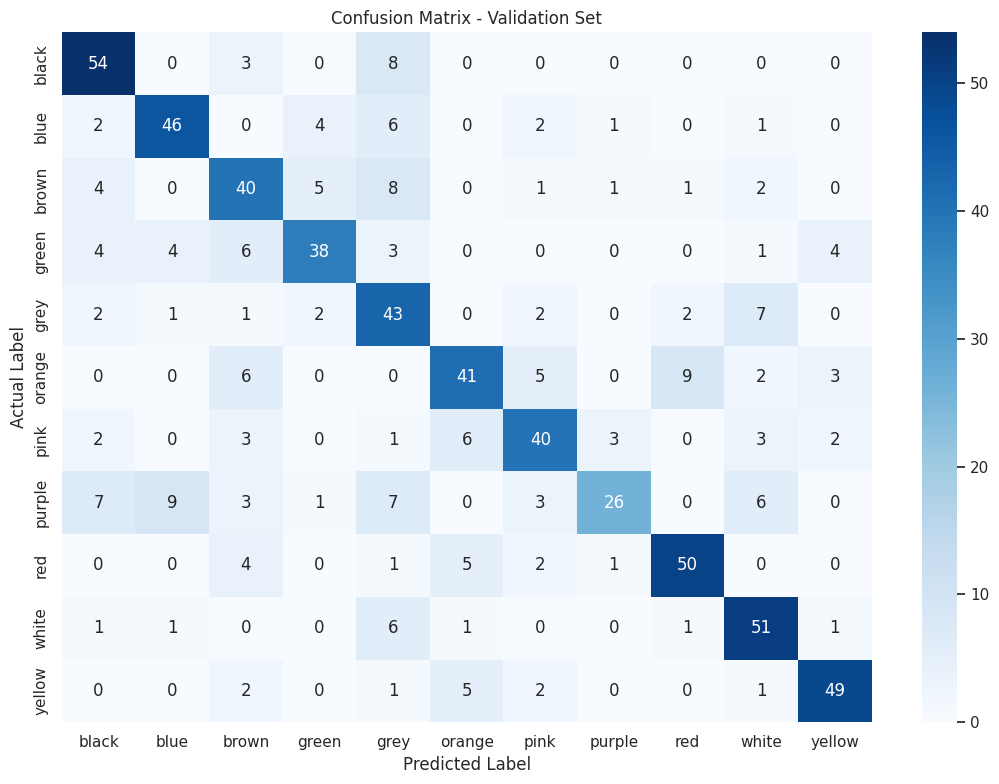

In [13]:
# Mengambil urutan kelas
class_names = np.unique(y_train)

cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=class_names
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Confusion Matrix - Validation Set')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

Eksprimen

In [14]:
# Menyimpan baseline eksperimen sebelumnya
baseline_results = results_sorted.copy()

baseline_best = baseline_results.iloc[0]

baseline_accuracy = baseline_best['Accuracy']
baseline_f1 = baseline_best['F1-Score']

print('BASELINE KNN')
print('Scaling:', baseline_best['Scaling'])
print('K:', baseline_best['K'])
print('Weights:', baseline_best['Weights'])
print('Metric:', baseline_best['Metric'])
print(f'Accuracy: {baseline_accuracy:.4f}')
print(f'Macro F1-Score: {baseline_f1:.4f}')

BASELINE KNN
Scaling: MinMaxScaler
K: 5
Weights: distance
Metric: euclidean
Accuracy: 0.7009
Macro F1-Score: 0.6984


## 9. Hyperparameter Tuning Lanjutan KNN

Pada tahap ini dilakukan optimasi lanjutan terhadap algoritma K-Nearest Neighbors (KNN) untuk memperoleh konfigurasi model yang lebih optimal.

Eksperimen menggunakan Grid Search dengan Stratified 5-Fold Cross Validation. Metode ini membagi data training menjadi lima bagian dengan tetap mempertahankan proporsi kelas pada setiap fold.

Parameter yang diuji meliputi jumlah tetangga terdekat (K), metode pembobotan, metrik jarak, dan metode feature scaling. Pipeline digunakan untuk memastikan proses scaling dilakukan secara benar pada setiap fold.

Konfigurasi terbaik dipilih berdasarkan nilai macro F1-score, kemudian dibandingkan dengan hasil eksperimen sebelumnya menggunakan validation set.

In [15]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.neighbors import KNeighborsClassifier

# Pipeline KNN
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_jobs=-1))
])

# Parameter yang diuji
param_grid = [
    {
        'scaler': ['passthrough', StandardScaler(), MinMaxScaler(), RobustScaler()],
        'knn__n_neighbors': list(range(1, 61)),
        'knn__weights': ['uniform', 'distance'],
        'knn__metric': ['euclidean', 'manhattan']
    },
    {
        'scaler': ['passthrough', StandardScaler(), MinMaxScaler(), RobustScaler()],
        'knn__n_neighbors': list(range(1, 61)),
        'knn__weights': ['uniform', 'distance'],
        'knn__metric': ['minkowski'],
        'knn__p': [1, 2, 3]
    }
]

# Stratified 5-Fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

# Training
grid_search.fit(X_train, y_train)

print('\nHyperparameter tuning selesai.')
print('Jumlah kombinasi:', len(grid_search.cv_results_['params']))
print('Best CV Macro F1:', grid_search.best_score_)
print('Best Parameters:')
print(grid_search.best_params_)

Fitting 5 folds for each of 2400 candidates, totalling 12000 fits

Hyperparameter tuning selesai.
Jumlah kombinasi: 2400
Best CV Macro F1: 0.6941414115490911
Best Parameters:
{'knn__metric': 'minkowski', 'knn__n_neighbors': 5, 'knn__p': 3, 'knn__weights': 'distance', 'scaler': MinMaxScaler()}


In [16]:
# Model terbaik dari Grid Search
best_knn_grid = grid_search.best_estimator_

# Prediksi validation set
y_val_grid_pred = best_knn_grid.predict(X_val)

# Menghitung metrik
grid_validation_metrics = {
    'Accuracy': accuracy_score(y_val, y_val_grid_pred),
    'Precision': precision_score(
        y_val, y_val_grid_pred,
        average='macro',
        zero_division=0
    ),
    'Recall': recall_score(
        y_val, y_val_grid_pred,
        average='macro',
        zero_division=0
    ),
    'F1-Score': f1_score(
        y_val, y_val_grid_pred,
        average='macro',
        zero_division=0
    )
}

display(
    pd.DataFrame(
        [grid_validation_metrics],
        index=['KNN GridSearch']
    ).round(4)
)

,Accuracy,Precision,Recall,F1-Score
KNN GridSearch,0.6994,0.7157,0.6992,0.699


In [17]:
comparison_df = pd.DataFrame([
    {
        'Model': 'Baseline KNN',
        'Accuracy': baseline_accuracy,
        'Macro F1': baseline_f1
    },
    {
        'Model': 'Tuned KNN',
        'Accuracy': grid_validation_metrics['Accuracy'],
        'Macro F1': grid_validation_metrics['F1-Score']
    }
])

display(comparison_df.round(4))

,Model,Accuracy,Macro F1
0,Baseline KNN,0.7009,0.6984
1,Tuned KNN,0.6994,0.6990


In [18]:
print('Best CV Macro F1:')
print(grid_search.best_score_)

print('\nBest Parameters:')
print(grid_search.best_params_)

Best CV Macro F1:
0.6941414115490911

Best Parameters:
{'knn__metric': 'minkowski', 'knn__n_neighbors': 5, 'knn__p': 3, 'knn__weights': 'distance', 'scaler': MinMaxScaler()}


In [19]:
print(
    classification_report(
        y_val,
        y_val_grid_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       black       0.71      0.82      0.76        65
        blue       0.75      0.74      0.75        62
       brown       0.58      0.65      0.61        62
       green       0.74      0.62      0.67        60
        grey       0.50      0.68      0.58        60
      orange       0.72      0.62      0.67        66
        pink       0.67      0.67      0.67        60
      purple       0.88      0.48      0.62        62
         red       0.79      0.78      0.78        63
       white       0.69      0.82      0.75        62
      yellow       0.84      0.82      0.83        60

    accuracy                           0.70       682
   macro avg       0.72      0.70      0.70       682
weighted avg       0.72      0.70      0.70       682



In [20]:
print('Best CV Macro F1:', grid_search.best_score_)

print('\nBest Parameters:')
print(grid_search.best_params_)

Best CV Macro F1: 0.6941414115490911

Best Parameters:
{'knn__metric': 'minkowski', 'knn__n_neighbors': 5, 'knn__p': 3, 'knn__weights': 'distance', 'scaler': MinMaxScaler()}


#SVM


In [21]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
# Daftar konfigurasi
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

kernels = ['linear', 'rbf', 'poly']

svm_results = []
svm_models = {}

# Eksperimen setiap kombinasi scaler dan kernel
for scaler_name, scaler in scalers.items():
    for kernel in kernels:

        model = Pipeline([
            ('scaler', scaler),
            ('svm', SVC(
                kernel=kernel,
                random_state=42
            ))
        ])

        # Training
        model.fit(X_train, y_train)

        # Prediksi validation
        y_pred = model.predict(X_val)

        # Evaluasi
        accuracy = accuracy_score(y_val, y_pred)
        precision = precision_score(
            y_val, y_pred, average='macro', zero_division=0
        )
        recall = recall_score(
            y_val, y_pred, average='macro', zero_division=0
        )
        f1 = f1_score(
            y_val, y_pred, average='macro', zero_division=0
        )

        config_name = f'{scaler_name} + {kernel}'

        svm_results.append({
            'Configuration': config_name,
            'Scaling': scaler_name,
            'Kernel': kernel,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'Macro F1': f1
        })

        svm_models[config_name] = model

# Tabel hasil
svm_results_df = pd.DataFrame(svm_results)

svm_results_df = svm_results_df.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

svm_results_df.round(4)

,Configuration,Scaling,Kernel,Accuracy,Precision,Recall,Macro F1
0,MinMaxScaler + poly,MinMaxScaler,poly,0.7962,0.7996,0.7962,0.7960
1,StandardScaler + linear,StandardScaler,linear,0.7346,0.7402,0.7337,0.7339
2,RobustScaler + linear,RobustScaler,linear,0.7273,0.7331,0.7271,0.7268
3,StandardScaler + rbf,StandardScaler,rbf,0.7185,0.7327,0.7182,0.7175
4,MinMaxScaler + rbf,MinMaxScaler,rbf,0.7155,0.7392,0.7152,0.7140
5,StandardScaler + poly,StandardScaler,poly,0.6569,0.7429,0.6563,0.6658
6,MinMaxScaler + linear,MinMaxScaler,linear,0.6598,0.6973,0.6584,0.6569
7,RobustScaler + rbf,RobustScaler,rbf,0.3284,0.6863,0.3276,0.3287
8,RobustScaler + poly,RobustScaler,poly,0.2522,0.7057,0.2515,0.2767


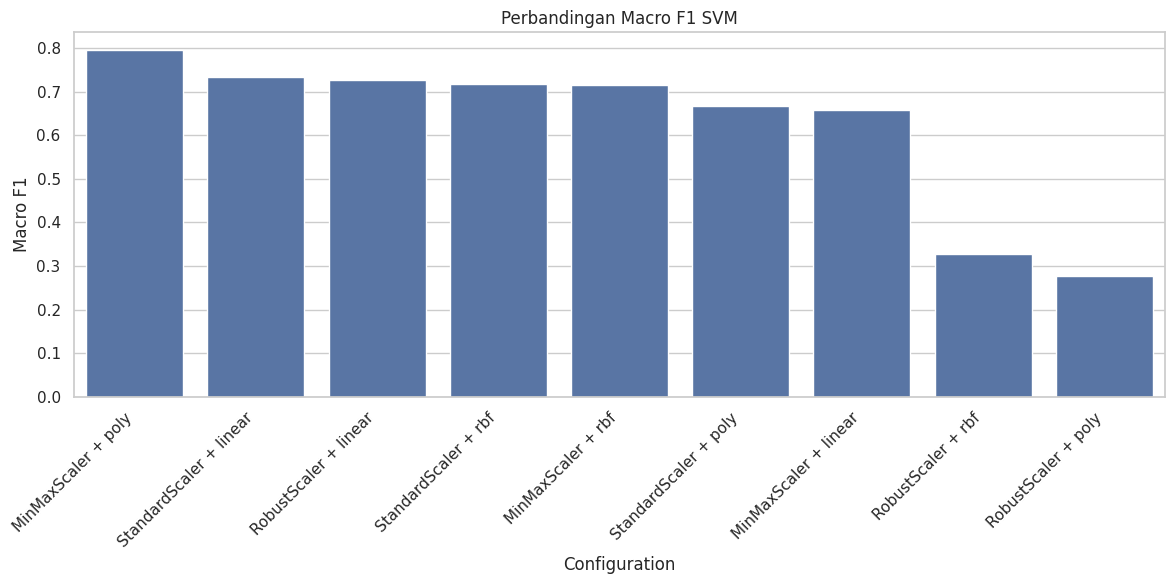

In [23]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=svm_results_df,
    x='Configuration',
    y='Macro F1'
)

plt.title('Perbandingan Macro F1 SVM')
plt.xlabel('Configuration')
plt.ylabel('Macro F1')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [24]:
# Classification report untuk SVM terbaik

best_svm_row = svm_results_df.iloc[0]

best_svm_name = best_svm_row['Configuration']
best_svm_model = svm_models[best_svm_name]

y_val_svm_pred = best_svm_model.predict(X_val)

print('Best SVM:', best_svm_name)
print('\nClassification Report:\n')

print(classification_report(
    y_val,
    y_val_svm_pred,
    zero_division=0
))

Best SVM: MinMaxScaler + poly

Classification Report:

              precision    recall  f1-score   support

       black       0.75      0.86      0.80        65
        blue       0.81      0.87      0.84        62
       brown       0.76      0.71      0.73        62
       green       0.87      0.90      0.89        60
        grey       0.71      0.68      0.69        60
      orange       0.74      0.74      0.74        66
        pink       0.74      0.75      0.74        60
      purple       0.88      0.69      0.77        62
         red       0.90      0.84      0.87        63
       white       0.75      0.84      0.79        62
      yellow       0.90      0.87      0.88        60

    accuracy                           0.80       682
   macro avg       0.80      0.80      0.80       682
weighted avg       0.80      0.80      0.80       682



In [25]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

svm_pipeline = Pipeline([
    ('scaler', MinMaxScaler()),
    ('svm', SVC(kernel='poly'))
])

param_grid_svm = {
    'svm__C': [0.1, 1, 10],
    'svm__degree': [2, 3, 4],
    'svm__gamma': ['scale', 'auto'],
    'svm__coef0': [0, 1]
}

cv_svm = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_svm = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_svm,
    scoring='f1_macro',
    cv=cv_svm,
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_svm.fit(X_train, y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', MinMaxScaler()),
                                       ('svm', SVC(kernel='poly'))]),
             n_jobs=-1,
             param_grid={'svm__C': [0.1, 1, 10], 'svm__coef0': [0, 1],
                         'svm__degree': [2, 3, 4],
                         'svm__gamma': ['scale', 'auto']},
             scoring='f1_macro', verbose=2)

In [27]:
print('Best CV Macro F1:', grid_svm.best_score_)

print('\nBest Parameters:')
print(grid_svm.best_params_)

Best CV Macro F1: 0.7977324473851896

Best Parameters:
{'svm__C': 10, 'svm__coef0': 1, 'svm__degree': 3, 'svm__gamma': 'scale'}


In [28]:
# Mengambil model terbaik dari GridSearchCV
best_svm_tuned = grid_svm.best_estimator_

# Prediksi data validation
y_val_svm_tuned_pred = best_svm_tuned.predict(X_val)

# Evaluasi
svm_tuned_accuracy = accuracy_score(
    y_val, y_val_svm_tuned_pred
)

svm_tuned_precision = precision_score(
    y_val, y_val_svm_tuned_pred,
    average='macro'
)

svm_tuned_recall = recall_score(
    y_val, y_val_svm_tuned_pred,
    average='macro'
)

svm_tuned_f1 = f1_score(
    y_val, y_val_svm_tuned_pred,
    average='macro'
)

print('TUNED SVM - VALIDATION RESULTS')
print('=' * 40)
print(f'Accuracy  : {svm_tuned_accuracy:.4f}')
print(f'Precision : {svm_tuned_precision:.4f}')
print(f'Recall    : {svm_tuned_recall:.4f}')
print(f'Macro F1  : {svm_tuned_f1:.4f}')

TUNED SVM - VALIDATION RESULTS
Accuracy  : 0.8138
Precision : 0.8160
Recall    : 0.8140
Macro F1  : 0.8142


In [29]:
print('Classification Report - Tuned SVM\n')

print(classification_report(
    y_val,
    y_val_svm_tuned_pred,
    zero_division=0
))

Classification Report - Tuned SVM

              precision    recall  f1-score   support

       black       0.79      0.88      0.83        65
        blue       0.84      0.84      0.84        62
       brown       0.78      0.74      0.76        62
       green       0.86      0.90      0.88        60
        grey       0.70      0.77      0.73        60
      orange       0.75      0.74      0.75        66
        pink       0.76      0.75      0.76        60
      purple       0.86      0.79      0.82        62
         red       0.88      0.81      0.84        63
       white       0.84      0.87      0.86        62
      yellow       0.91      0.87      0.89        60

    accuracy                           0.81       682
   macro avg       0.82      0.81      0.81       682
weighted avg       0.82      0.81      0.81       682



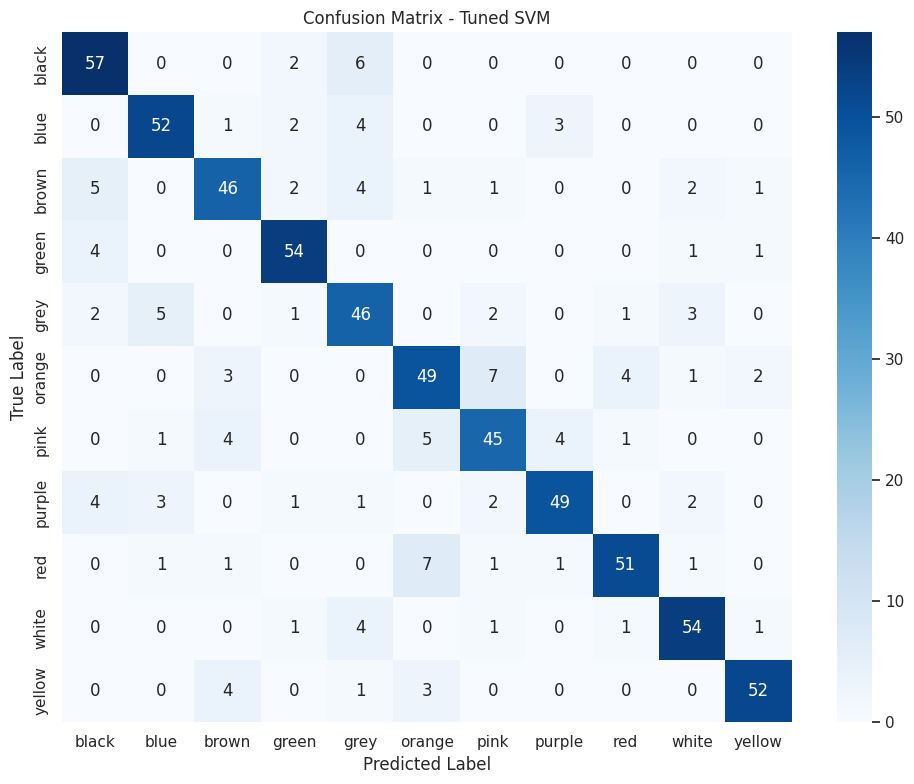

In [30]:
cm_svm_tuned = confusion_matrix(
    y_val,
    y_val_svm_tuned_pred,
    labels=class_names
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_svm_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title('Confusion Matrix - Tuned SVM')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

### Analisis Confusion Matrix Tuned SVM

Berdasarkan confusion matrix, model SVM dengan konfigurasi terbaik mampu mengklasifikasikan sebagian besar citra warna dengan benar. Hal ini ditunjukkan oleh banyaknya nilai pada diagonal utama yang merepresentasikan jumlah prediksi benar.

Beberapa kelas dengan jumlah prediksi benar tertinggi antara lain:
- Green: 54 dari 60 citra.
- White: 54 dari 62 citra.
- Blue: 52 dari 62 citra.
- Yellow: 52 dari 60 citra.

Sementara itu, masih terdapat beberapa kesalahan klasifikasi yang cukup menonjol, yaitu:
- Orange diprediksi sebagai Pink sebanyak 7 citra.
- Red diprediksi sebagai Orange sebanyak 7 citra.
- Black diprediksi sebagai Grey sebanyak 6 citra.
- Grey diprediksi sebagai Blue sebanyak 5 citra.
- Brown diprediksi sebagai Black sebanyak 5 citra.

Kesalahan tersebut menunjukkan bahwa model masih mengalami kesulitan dalam membedakan beberapa warna yang memiliki karakteristik fitur RGB berdekatan.

### Kesimpulan Evaluasi SVM

Berdasarkan hasil evaluasi pada validation set, model SVM dengan MinMaxScaler dan kernel Polynomial setelah hyperparameter tuning memperoleh hasil sebagai berikut:

- Accuracy: 81.38%
- Precision: 81.60%
- Recall: 81.40%
- Macro F1: 81.42%

Hasil tersebut menunjukkan bahwa proses hyperparameter tuning berhasil meningkatkan performa SVM dibandingkan konfigurasi baseline. Model ini menjadi kandidat terbaik sementara dibandingkan model KNN yang telah diuji sebelumnya.

### Tahap Selanjutnya

Untuk memperoleh pembanding dari algoritma yang berbeda, eksperimen dilanjutkan menggunakan Random Forest. Algoritma ini akan dilatih dan dievaluasi menggunakan data training dan validation yang sama.

Hasil eksperimen Random Forest nantinya akan dibandingkan dengan KNN dan SVM berdasarkan Accuracy, Precision, Recall, dan Macro F1 untuk menentukan model terbaik.

Data test tetap disimpan dan belum digunakan pada tahap pemilihan model.

#Random Forest Model Experiment

Pada tahap ini dilakukan eksperimen klasifikasi menggunakan algoritma Random Forest sebagai model pembanding terhadap KNN dan SVM.

Random Forest merupakan algoritma ensemble learning yang menggabungkan beberapa Decision Tree untuk menghasilkan prediksi klasifikasi. Setiap pohon menghasilkan prediksi, kemudian hasilnya digabungkan melalui mekanisme voting untuk menentukan kelas akhir.

Eksperimen dilakukan menggunakan data training dan validation yang sama dengan eksperimen sebelumnya. Pada tahap awal, digunakan konfigurasi baseline Random Forest tanpa hyperparameter tuning.

Berbeda dengan KNN dan SVM, Random Forest berbasis pohon keputusan sehingga tidak memerlukan proses feature scaling.

In [31]:
from sklearn.ensemble import RandomForestClassifier

# Inisialisasi model Random Forest
rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Training model
rf_model.fit(X_train, y_train)

print('Random Forest baseline training selesai.')

Random Forest baseline training selesai.


In [32]:
# Prediksi data validation
y_val_rf_pred = rf_model.predict(X_val)

# Menghitung metrik evaluasi
rf_accuracy = accuracy_score(y_val, y_val_rf_pred)

rf_precision = precision_score(
    y_val, y_val_rf_pred,
    average='macro',
    zero_division=0
)

rf_recall = recall_score(
    y_val, y_val_rf_pred,
    average='macro',
    zero_division=0
)

rf_f1 = f1_score(
    y_val, y_val_rf_pred,
    average='macro',
    zero_division=0
)

# Menampilkan hasil
print('RANDOM FOREST - BASELINE RESULTS')
print('=' * 40)
print(f'Accuracy  : {rf_accuracy:.4f}')
print(f'Precision : {rf_precision:.4f}')
print(f'Recall    : {rf_recall:.4f}')
print(f'Macro F1  : {rf_f1:.4f}')

RANDOM FOREST - BASELINE RESULTS
Accuracy  : 0.7317
Precision : 0.7404
Recall    : 0.7316
Macro F1  : 0.7312


In [33]:
print('Classification Report - Random Forest Baseline\n')

print(classification_report(
    y_val,
    y_val_rf_pred,
    zero_division=0
))

Classification Report - Random Forest Baseline

              precision    recall  f1-score   support

       black       0.73      0.85      0.79        65
        blue       0.73      0.71      0.72        62
       brown       0.66      0.65      0.65        62
       green       0.75      0.63      0.68        60
        grey       0.57      0.77      0.66        60
      orange       0.78      0.65      0.71        66
        pink       0.63      0.68      0.66        60
      purple       0.84      0.61      0.71        62
         red       0.83      0.78      0.80        63
       white       0.75      0.87      0.81        62
      yellow       0.86      0.85      0.86        60

    accuracy                           0.73       682
   macro avg       0.74      0.73      0.73       682
weighted avg       0.74      0.73      0.73       682



In [34]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

cv_rf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_param_grid,
    scoring='f1_macro',
    cv=cv_rf,
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_rf.fit(X_train, y_train)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


GridSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(n_jobs=1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_leaf': [1, 2],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200, 300]},
             scoring='f1_macro', verbose=2)

In [35]:
print('Best CV Macro F1:', grid_rf.best_score_)
print('Best Parameters:', grid_rf.best_params_)

Best CV Macro F1: 0.7216265675900874
Best Parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}


In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

best_rf = grid_rf.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_val)

print('Accuracy :', accuracy_score(y_val, y_pred_rf_tuned))
print('Precision:', precision_score(y_val, y_pred_rf_tuned, average='macro'))
print('Recall   :', recall_score(y_val, y_pred_rf_tuned, average='macro'))
print('Macro F1 :', f1_score(y_val, y_pred_rf_tuned, average='macro'))

Accuracy : 0.7346041055718475
Precision: 0.7452627596537563
Recall   : 0.7344524650976264
Macro F1 : 0.7338008393073224


In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_pred_rf_tuned))

              precision    recall  f1-score   support

       black       0.75      0.83      0.79        65
        blue       0.71      0.81      0.76        62
       brown       0.62      0.65      0.63        62
       green       0.72      0.63      0.67        60
        grey       0.59      0.75      0.66        60
      orange       0.76      0.67      0.71        66
        pink       0.67      0.70      0.68        60
      purple       0.90      0.56      0.69        62
         red       0.88      0.78      0.82        63
       white       0.74      0.87      0.80        62
      yellow       0.86      0.83      0.85        60

    accuracy                           0.73       682
   macro avg       0.75      0.73      0.73       682
weighted avg       0.75      0.73      0.73       682



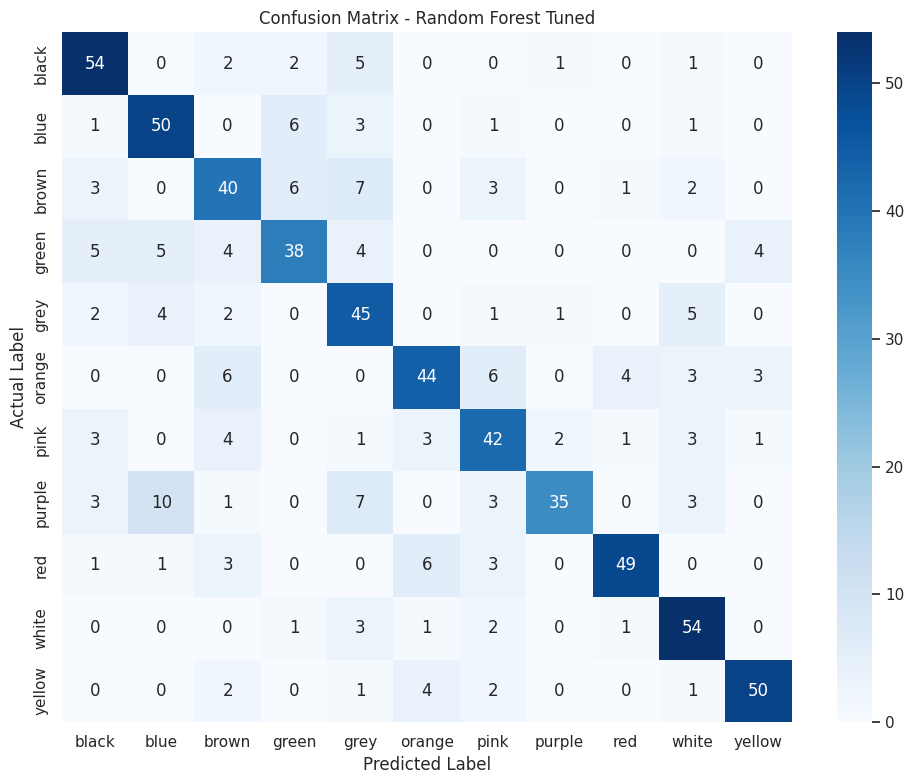

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_rf_tuned = confusion_matrix(y_val, y_pred_rf_tuned)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_rf_tuned,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_rf.classes_,
    yticklabels=best_rf.classes_
)

plt.title('Confusion Matrix - Random Forest Tuned')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Analisis Confusion Matrix Random Forest Tuned

Berdasarkan confusion matrix, model Random Forest hasil hyperparameter tuning mampu mengklasifikasikan sebagian besar citra dengan benar, yang ditunjukkan oleh nilai pada diagonal utama. Namun, masih terdapat beberapa kesalahan klasifikasi antarwarna.

Kesalahan paling banyak terjadi pada kelas purple yang diprediksi sebagai blue sebanyak 10 citra. Selain itu, terdapat 7 citra brown yang diprediksi sebagai grey, serta masing-masing 6 citra orange yang diprediksi sebagai brown dan pink.

Berdasarkan classification report, kelas yellow memperoleh F1-score tertinggi sebesar 0,85, sedangkan kelas brown memperoleh F1-score terendah sebesar 0,63. Hal ini menunjukkan bahwa kemampuan model dalam mengenali setiap kelas warna masih belum merata.

Secara keseluruhan, model Random Forest hasil tuning memperoleh accuracy sebesar 73,46% dan macro F1-score sebesar 73,38%. Hasil ini menunjukkan adanya sedikit peningkatan dibandingkan model Random Forest baseline, tetapi performanya masih berada di bawah model SVM hasil tuning.

# Perbandingan Performa Model

In [39]:
import pandas as pd

comparison_results = pd.DataFrame({
    'Model': ['KNN Tuned', 'SVM Tuned', 'Random Forest Tuned'],
    'Accuracy': [0.6994, 0.8138, 0.7346],
    'Macro F1': [0.6990, 0.8142, 0.7338]
})

comparison_results = comparison_results.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

comparison_results

,Model,Accuracy,Macro F1
0,SVM Tuned,0.8138,0.8142
1,Random Forest Tuned,0.7346,0.7338
2,KNN Tuned,0.6994,0.6990


### Analisis Perbandingan Model

Berdasarkan hasil evaluasi pada validation set, model SVM hasil hyperparameter tuning memperoleh performa terbaik dengan accuracy sebesar 81,38% dan macro F1-score sebesar 81,42%.

Random Forest hasil tuning memperoleh accuracy sebesar 73,46% dan macro F1-score sebesar 73,38%, sedangkan KNN hasil tuning memperoleh accuracy sebesar 69,94% dan macro F1-score sebesar 69,90%.

Dengan demikian, SVM dipilih sebagai model terbaik karena menghasilkan nilai accuracy dan macro F1-score tertinggi dibandingkan kedua algoritma lainnya. Model ini selanjutnya akan digunakan untuk evaluasi akhir menggunakan test set.

In [40]:
# Mengambil model SVM terbaik hasil tuning
best_svm = grid_svm.best_estimator_

# Prediksi menggunakan data test
y_pred_svm_test = best_svm.predict(X_test)

print('Prediksi pada test set selesai.')

Prediksi pada test set selesai.


In [41]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_test = accuracy_score(y_test, y_pred_svm_test)
precision_test = precision_score(y_test, y_pred_svm_test, average='macro')
recall_test = recall_score(y_test, y_pred_svm_test, average='macro')
f1_test = f1_score(y_test, y_pred_svm_test, average='macro')

print('Accuracy :', accuracy_test)
print('Precision:', precision_test)
print('Recall   :', recall_test)
print('Macro F1 :', f1_test)

Accuracy : 0.8137829912023461
Precision: 0.8172660324799406
Recall   : 0.8142951969178952
Macro F1 : 0.8132487014061429


### Evaluasi Akhir Model SVM pada Test Set

Evaluasi akhir dilakukan menggunakan test set yang sebelumnya tidak digunakan dalam proses pelatihan maupun hyperparameter tuning. Berdasarkan hasil pengujian, model SVM hasil tuning memperoleh accuracy sebesar 81,38%, precision sebesar 81,73%, recall sebesar 81,43%, dan macro F1-score sebesar 81,32%.

Hasil evaluasi menunjukkan bahwa performa model pada test set relatif konsisten dengan hasil validation set. Macro F1-score pada validation set sebesar 81,42%, sedangkan pada test set sebesar 81,32%. Selisih yang kecil menunjukkan bahwa model mampu mempertahankan performanya pada data yang belum pernah digunakan sebelumnya.

Dengan demikian, model SVM hasil hyperparameter tuning ditetapkan sebagai model terbaik untuk klasifikasi 11 kategori warna berdasarkan fitur dominan RGB.

In [42]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_svm_test))

              precision    recall  f1-score   support

       black       0.81      0.86      0.84        65
        blue       0.83      0.94      0.88        63
       brown       0.75      0.85      0.80        61
       green       0.87      0.90      0.88        59
        grey       0.72      0.77      0.74        60
      orange       0.81      0.76      0.78        66
        pink       0.75      0.82      0.78        60
      purple       0.85      0.65      0.74        63
         red       0.89      0.86      0.87        63
       white       0.78      0.75      0.76        63
      yellow       0.92      0.81      0.86        59

    accuracy                           0.81       682
   macro avg       0.82      0.81      0.81       682
weighted avg       0.82      0.81      0.81       682



### Analisis Classification Report SVM pada Test Set

Berdasarkan classification report pada test set, model SVM hasil hyperparameter tuning menunjukkan performa yang bervariasi pada setiap kelas warna.

Kelas blue dan green memperoleh F1-score tertinggi sebesar 0,88, diikuti red sebesar 0,87 dan yellow sebesar 0,86. Hal ini menunjukkan bahwa model mampu mengenali kelas-kelas tersebut dengan cukup baik.

Sementara itu, kelas purple dan grey memperoleh F1-score terendah, masing-masing sebesar 0,74. Khusus kelas purple, nilai recall sebesar 0,65 menunjukkan bahwa model masih mengalami kesulitan dalam mengenali seluruh citra purple dengan tepat.

Secara keseluruhan, model memperoleh accuracy sebesar 81%, dengan macro average F1-score sebesar 0,81. Hasil ini menunjukkan bahwa model SVM mampu melakukan klasifikasi terhadap 11 kategori warna dengan performa yang relatif baik.

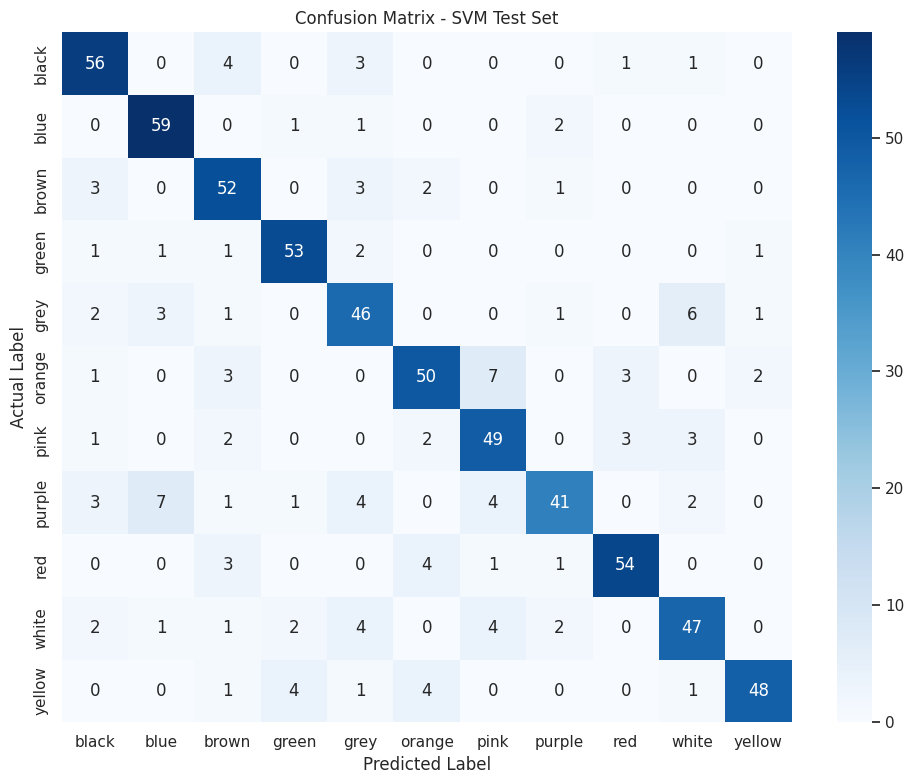

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_svm_test = confusion_matrix(y_test, y_pred_svm_test)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_svm_test,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_svm.classes_,
    yticklabels=best_svm.classes_
)

plt.title('Confusion Matrix - SVM Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Analisis Confusion Matrix SVM pada Test Set

Berdasarkan confusion matrix, model SVM hasil hyperparameter tuning mampu mengklasifikasikan sebagian besar citra dengan benar. Hal ini ditunjukkan oleh nilai prediksi yang terkonsentrasi pada diagonal utama.

Kelas blue memiliki jumlah prediksi benar sebanyak 59 dari 63 citra, sedangkan kelas green berhasil dikenali sebanyak 53 dari 59 citra. Sebaliknya, kelas purple memiliki jumlah prediksi benar sebanyak 41 dari 63 citra, sehingga menjadi salah satu kelas yang paling sulit dikenali oleh model.

Beberapa kesalahan klasifikasi yang menonjol terjadi pada kelas orange yang diprediksi sebagai pink sebanyak 7 citra, serta kelas purple yang diprediksi sebagai blue sebanyak 7 citra. Selain itu, terdapat 6 citra grey yang diprediksi sebagai white.

Secara keseluruhan, confusion matrix memperlihatkan bahwa model SVM mampu mengenali sebagian besar kategori warna dengan baik, meskipun masih terdapat kesalahan klasifikasi pada beberapa kelas. Hasil ini sejalan dengan evaluasi test set yang menghasilkan accuracy sebesar 81,38% dan macro F1-score sebesar 81,32%.

**Simpan model**

In [47]:
import joblib
import os

model_dir = '/content/drive/MyDrive/color-detection/model'

model_path = os.path.join(model_dir, 'svm_color_model.joblib')

joblib.dump(best_svm, model_path)

print('Model berhasil disimpan!')
print('Lokasi:', model_path)

Model berhasil disimpan!
Lokasi: /content/drive/MyDrive/color-detection/model/svm_color_model.joblib


In [49]:
import json
import os

metadata = {
    'model_name': 'SVM Color Classifier',
    'model_type': 'Support Vector Machine',
    'model_file': 'svm_color_model.joblib',
    'classes': [
        'black', 'blue', 'brown', 'green', 'grey',
        'orange', 'pink', 'purple', 'red', 'white', 'yellow'
    ],
    'feature_extraction': {
        'method': 'K-Means',
        'n_clusters': 3,
        'features_per_image': 9,
        'color_space': 'RGB',
        'channel_order': ['R', 'G', 'B']
    },
    'scaler': 'MinMaxScaler',
    'best_parameters': {
        'C': 10,
        'kernel': 'poly',
        'degree': 3,
        'gamma': 'scale',
        'coef0': 1
    },
    'evaluation': {
        'accuracy': 0.8138,
        'precision_macro': 0.8173,
        'recall_macro': 0.8143,
        'f1_macro': 0.8132
    }
}

metadata_path = os.path.join(model_dir, 'metadata.json')

with open(metadata_path, 'w') as file:
    json.dump(metadata, file, indent=4)

print('Metadata berhasil disimpan!')
print('Lokasi:', metadata_path)

Metadata berhasil disimpan!
Lokasi: /content/drive/MyDrive/color-detection/model/metadata.json


In [50]:
with open(metadata_path, 'r') as file:
    loaded_metadata = json.load(file)

print(json.dumps(loaded_metadata, indent=4))

{
    "model_name": "SVM Color Classifier",
    "model_type": "Support Vector Machine",
    "model_file": "svm_color_model.joblib",
    "classes": [
        "black",
        "blue",
        "brown",
        "green",
        "grey",
        "orange",
        "pink",
        "purple",
        "red",
        "white",
        "yellow"
    ],
    "feature_extraction": {
        "method": "K-Means",
        "n_clusters": 3,
        "features_per_image": 9,
        "color_space": "RGB",
        "channel_order": [
            "R",
            "G",
            "B"
        ]
    },
    "scaler": "MinMaxScaler",
    "best_parameters": {
        "C": 10,
        "kernel": "poly",
        "degree": 3,
        "gamma": "scale",
        "coef0": 1
    },
    "evaluation": {
        "accuracy": 0.8138,
        "precision_macro": 0.8173,
        "recall_macro": 0.8143,
        "f1_macro": 0.8132
    }
}



# Interpretasi Keseluruhan Proses Pemodelan

## 1. Gambaran Umum Pemodelan

Tahap pemodelan dilakukan untuk membangun model klasifikasi warna berdasarkan fitur warna dominan yang telah diekstraksi dari setiap gambar menggunakan metode K-Means. Dataset terdiri dari 4.545 gambar yang dikelompokkan ke dalam 11 kelas warna, yaitu black, blue, brown, green, grey, orange, pink, purple, red, white, dan yellow.

Pada tahap preprocessing, setiap gambar direpresentasikan menggunakan tiga warna dominan dalam format RGB. Dengan demikian, setiap gambar memiliki sembilan fitur numerik yang terdiri dari tiga komponen RGB untuk masing-masing warna dominan.

Dataset dibagi menjadi tiga bagian menggunakan metode stratified splitting dengan proporsi:
- Data training: 70% (3.181 data).
- Data validation: 15% (682 data).
- Data testing: 15% (682 data).

Pembagian secara stratified dilakukan untuk mempertahankan proporsi setiap kelas warna pada masing-masing subset data.

## 2. Pelatihan dan Hyperparameter Tuning

Tiga algoritma Machine Learning digunakan dan dibandingkan dalam proses klasifikasi, yaitu K-Nearest Neighbors (KNN), Support Vector Machine (SVM), dan Random Forest.

Sebelum pelatihan, dilakukan eksperimen menggunakan beberapa konfigurasi preprocessing dan parameter model untuk memperoleh performa terbaik.

Hyperparameter tuning dilakukan menggunakan GridSearchCV dengan Stratified K-Fold Cross Validation sebanyak tiga fold dan Macro F1-Score sebagai metrik utama. Penggunaan Macro F1-Score bertujuan agar performa setiap kelas warna diperhitungkan secara seimbang.

Hasil tuning menunjukkan konfigurasi terbaik sebagai berikut:

- **KNN:** menggunakan MinMaxScaler dengan 5 neighbors, distance weighting, dan Minkowski distance dengan p = 3.
- **SVM:** menggunakan MinMaxScaler dengan kernel polynomial, C = 10, degree = 3, gamma = scale, dan coef0 = 1.
- **Random Forest:** menggunakan 300 decision trees, max_depth = 20, min_samples_split = 5, dan min_samples_leaf = 1.

## 3. Perbandingan Performa Model

Setelah proses tuning selesai, ketiga model dievaluasi menggunakan validation set. Hasil perbandingan performanya adalah sebagai berikut:

| Model | Accuracy | Macro F1-Score |
|---|---:|---:|
| SVM Tuned | 81,38% | 81,42% |
| Random Forest Tuned | 73,46% | 73,38% |
| KNN Tuned | 69,94% | 69,90% |

Berdasarkan hasil tersebut, SVM memperoleh performa terbaik dengan Accuracy sebesar 81,38% dan Macro F1-Score sebesar 81,42%.

Random Forest berada pada posisi kedua dengan Macro F1-Score sebesar 73,38%, sedangkan KNN memperoleh Macro F1-Score sebesar 69,90%.

Hasil ini menunjukkan bahwa SVM lebih mampu memisahkan karakteristik fitur warna dominan pada dataset dibandingkan kedua algoritma lainnya.

Oleh karena itu, model SVM hasil hyperparameter tuning dipilih sebagai model terbaik untuk tahap evaluasi akhir.

## 4. Evaluasi Model Terbaik pada Test Set

Model SVM terbaik selanjutnya dievaluasi menggunakan test set yang sebelumnya tidak digunakan dalam proses pelatihan maupun pemilihan hyperparameter.

Hasil evaluasi akhir menunjukkan:

| Metrik | Hasil |
|---|---:|
| Accuracy | 81,38% |
| Precision (Macro) | 81,73% |
| Recall (Macro) | 81,43% |
| F1-Score (Macro) | 81,32% |

Accuracy sebesar 81,38% menunjukkan bahwa model mampu mengklasifikasikan sekitar 81 dari setiap 100 gambar dengan benar pada test set.

Berdasarkan classification report, beberapa kelas memiliki performa yang relatif baik. Kelas blue memperoleh Recall sebesar 94%, green sebesar 90%, dan red sebesar 86%. Hal ini menunjukkan bahwa model cukup baik dalam mengenali ketiga kelas tersebut.

Namun, masih terdapat beberapa kelas yang lebih sulit dikenali. Kelas purple memiliki Recall sebesar 65%, sedangkan grey sebesar 77%, white sebesar 75%, orange sebesar 76%, dan pink sebesar 82%.

Berdasarkan confusion matrix, beberapa kesalahan klasifikasi yang terlihat antara lain:
- Purple diprediksi sebagai blue sebanyak 7 data.
- Orange diprediksi sebagai pink sebanyak 7 data.
- Grey diprediksi sebagai white sebanyak 6 data.
- Black diprediksi sebagai brown sebanyak 4 data.
- Red diprediksi sebagai orange sebanyak 4 data.

Kesalahan tersebut menunjukkan bahwa beberapa warna memiliki karakteristik RGB dominan yang berdekatan sehingga masih dapat menghasilkan prediksi yang keliru.

Secara keseluruhan, hasil evaluasi pada test set menunjukkan performa yang konsisten dengan validation set. Hal ini terlihat dari nilai Accuracy dan Macro F1-Score yang relatif sama, sehingga tidak ditemukan penurunan performa yang berarti pada data pengujian.

## 5. Penyimpanan Model dan Pembuatan Metadata

Setelah evaluasi akhir, model SVM terbaik disimpan menggunakan library Joblib dalam format `.joblib` dengan nama `svm_color_model.joblib`.

Model disimpan dalam bentuk pipeline yang mencakup dua tahapan, yaitu MinMaxScaler dan SVM. Penyimpanan dalam bentuk pipeline memungkinkan proses normalisasi fitur dan klasifikasi dilakukan secara berurutan ketika model digunakan kembali.

Selain model, dibuat file `metadata.json` yang berisi informasi pendukung untuk kebutuhan integrasi model ke dalam aplikasi. Metadata ini berfungsi sebagai dokumentasi konfigurasi model dan karakteristik fitur yang digunakan.

Informasi yang disimpan dalam metadata meliputi:

- **Identitas model:** nama model, jenis algoritma, dan nama file model.
- **Daftar kelas:** 11 kategori warna yang digunakan dalam klasifikasi.
- **Ekstraksi fitur:** metode K-Means dengan tiga cluster, sembilan fitur RGB, serta urutan kanal R, G, dan B.
- **Scaler:** MinMaxScaler yang digunakan dalam pipeline.
- **Parameter terbaik:** konfigurasi hyperparameter SVM hasil GridSearchCV.
- **Evaluasi model:** nilai Accuracy, Precision, Recall, dan Macro F1-Score pada test set.

Dengan adanya metadata, informasi mengenai model dan format fitur dapat diketahui tanpa harus memeriksa kembali seluruh proses pelatihan. Hal ini juga membantu anggota yang bertanggung jawab pada pengembangan aplikasi dalam memahami konfigurasi model yang akan diintegrasikan.

## 6. Verifikasi Model dan Metadata

Setelah model dan metadata berhasil disimpan, dilakukan beberapa pengujian untuk memastikan keduanya dapat digunakan kembali.

### 6.1 Verifikasi Pemuatan Model

Model yang telah disimpan dimuat kembali menggunakan `joblib.load()`. Hasil pengujian menunjukkan bahwa model berhasil dimuat dalam bentuk objek `Pipeline` yang terdiri dari dua tahapan, yaitu `scaler` dan `svm`.

Hal ini menunjukkan bahwa struktur pipeline tetap terjaga setelah proses penyimpanan dan pemuatan kembali.

### 6.2 Verifikasi Konsistensi Prediksi

Verifikasi dilakukan dengan membandingkan hasil prediksi lima sampel pertama dari model sebelum dan sesudah proses penyimpanan.

Hasil pengujian menunjukkan bahwa kedua model menghasilkan prediksi yang identik, yaitu:

- Prediksi model tersimpan: `['pink', 'blue', 'grey', 'green', 'pink']`
- Prediksi model sebelumnya: `['pink', 'blue', 'grey', 'green', 'pink']`
- Hasil verifikasi: `True`

Nilai `True` menunjukkan bahwa model yang telah dimuat kembali menghasilkan prediksi yang sama dengan model sebelumnya.

### 6.3 Verifikasi Metadata

File `metadata.json` juga berhasil dibaca kembali menggunakan library JSON tanpa mengalami kesalahan.

Selanjutnya, dilakukan pemeriksaan terhadap kesesuaian daftar kelas pada metadata dengan daftar kelas yang tersimpan dalam model SVM.

Hasil pemeriksaan menunjukkan bahwa urutan 11 kelas warna pada metadata sama dengan urutan kelas pada model, dengan hasil verifikasi `True`.

Dengan demikian, informasi kelas dalam metadata telah sesuai dengan model klasifikasi dan dapat digunakan sebagai referensi dalam proses integrasi aplikasi.

## 7. Kesimpulan Pemodelan

Berdasarkan seluruh tahapan yang telah dilakukan, algoritma Support Vector Machine (SVM) dengan kernel polynomial merupakan model terbaik di antara tiga algoritma yang diuji.

Model memperoleh Accuracy sebesar 81,38% dan Macro F1-Score sebesar 81,32% pada test set. Hasil tersebut menunjukkan bahwa model memiliki kemampuan yang cukup baik dalam mengklasifikasikan 11 kategori warna berdasarkan tiga warna dominan yang direpresentasikan dalam sembilan fitur RGB.

Meskipun demikian, model masih mengalami kesulitan dalam membedakan beberapa kelas warna yang memiliki karakteristik serupa, terutama purple, blue, grey, dan white. Hal ini menjadi salah satu aspek yang dapat diperhatikan dalam pengembangan sistem selanjutnya.

Model SVM terpilih telah berhasil disimpan dalam format `.joblib`, disertai file `metadata.json` yang berisi informasi konfigurasi model dan fitur. Kedua file juga telah berhasil dimuat dan diverifikasi.

Dengan demikian, hasil pemodelan telah dipersiapkan untuk tahap selanjutnya, yaitu integrasi model, metadata, serta fungsi preprocessing dan ekstraksi fitur ke dalam aplikasi klasifikasi warna menggunakan Streamlit.
